In [29]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from single_cell_simulations import (find_spike_rate,
                                     psd_welch,
                                     welch_psd_fixed_resolution,
                                     calculate_band_snr_and_zscore,
                                     calculate_spectral_snr_and_zscore,
                                     )

In [31]:
save_dir = "results"

dt = 0.025

noise_type = "ou"

noise_level_Vm = 5.
force_rerun = False
carrier_f = 2000.
beat_f = 20.
firing_rate_bin_size = dt

sim_params = dict(
    sim_time=5000e3,
    target_stim_dVm=0.3,
    f_values=[carrier_f],
    noise_level_Vm=noise_level_Vm,
    seed=2,
    V_th=-50.,
    resolution=dt,
    sim_name=f"Fig1G-I_dt:{dt}_{carrier_f}_{beat_f}_{noise_type}",
    force_rerun=force_rerun,
    description="1000 Hz stimulation",
    save_Vm="full",
    noise_type=noise_type,
)
sim_time = sim_params["sim_time"]


sim_name = sim_params["sim_name"]
save_path = os.path.join(save_dir, f"{sim_name}.pkl")
with open(save_path, "rb") as f:
    spiketimes = pickle.load(f)["results"]["spike_times"]

spike_rate, t_bins = find_spike_rate(
    spiketimes, firing_rate_bin_size, sim_time)



In [32]:
spiketimes

array([4.83725000e+02, 5.33750000e+02, 6.87175000e+02, ...,
       4.99968362e+06, 4.99980773e+06, 4.99993817e+06], shape=(15987,))

In [33]:
welch_segments = 4

fs_fr = 1000. / firing_rate_bin_size
# print(f"Sampling rate: {fs_fr} Hz")
freqs_fr, fr_psd = welch(spike_rate, fs=fs_fr, nperseg=len(spike_rate) // welch_segments,
                          noverlap=(len(spike_rate) // welch_segments) // 2)

freq_resolution = 0.005
freqs_fr_fixed_res, fr_psd_fixed_res = welch_psd_fixed_resolution(
    spike_rate, fs_fr, freq_resolution=freq_resolution)


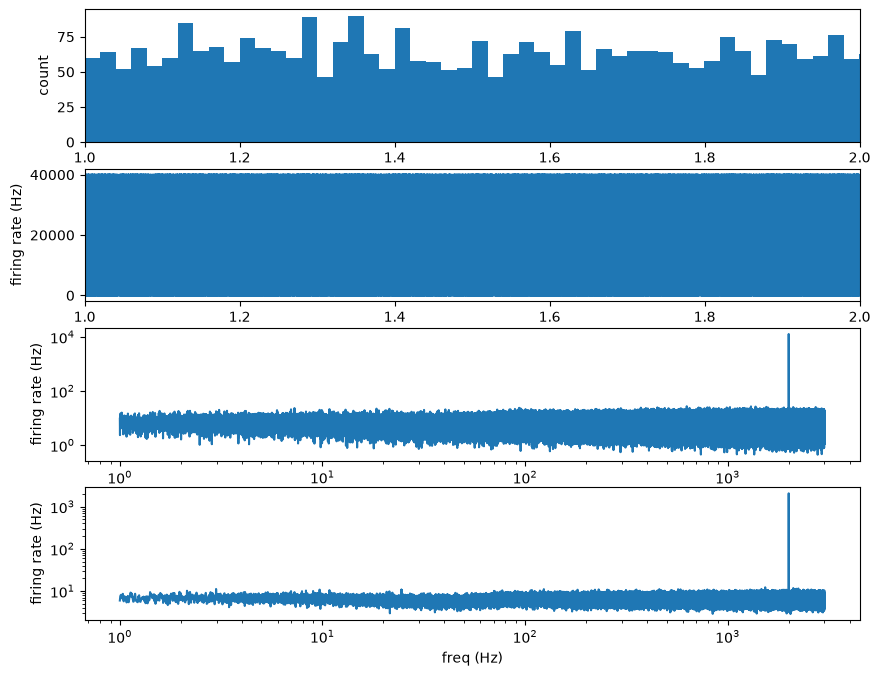

In [36]:
plt.close("all")
fig = plt.figure(figsize=(10, 10))
ax1 = fig.add_subplot(511, xlabel="time (ms)", ylabel="count", xlim=(1000e3, 2000e3))
ax2 = fig.add_subplot(512, xlabel="time (ms)", ylabel="firing rate (Hz)", xlim=(1000e3, 2000e3))
ax3 = fig.add_subplot(513, xlabel="freq (Hz)", ylabel="firing rate (Hz)",)
ax4 = fig.add_subplot(514, xlabel="freq (Hz)", ylabel="firing rate (Hz)",)

mask_spiketimes = (spiketimes > 1000e3) & (spiketimes < 3000e3)
mask_bins = (t_bins[:-1] > 1000e3) & (t_bins[:-1] < 3000e3)


ax1.hist(spiketimes[mask_spiketimes], bins=100)
ax2.plot(t_bins[:-1][mask_bins], spike_rate[mask_bins])

min_freq = 1
max_freq = 3000
freq_mask_fixed_res = (freqs_fr_fixed_res >= min_freq) & (freqs_fr_fixed_res <= max_freq)
freq_mask = (freqs_fr >= min_freq) & (freqs_fr <= max_freq)

ax3.loglog(freqs_fr[freq_mask], fr_psd[freq_mask])
ax4.loglog(freqs_fr_fixed_res[freq_mask_fixed_res], fr_psd_fixed_res[freq_mask_fixed_res])


N = 15987 spikes, mean rate = 3.197 spikes/s, mean ISI = 312.8 ms
Analysis grid: nb = 50000000 bins (200 MB as float32), frequency resolution = 0.2 mHz, Nyquist = 5000 Hz
Bins tested in 1-3000 Hz: 2.500e+07
Per-bin 95% line at I = 3.00; family-wise 95% (Bonferroni) line at I = 20.03
Sanity check: mean(I) in (100.0, 1000.0) Hz = 1.0005 (expect 1)


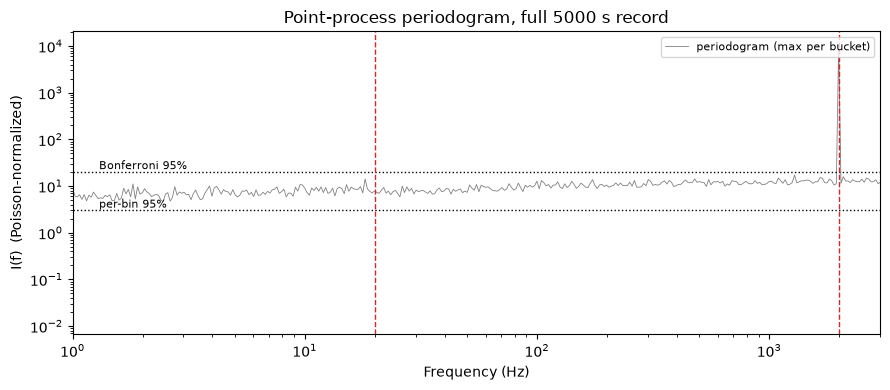

f0 = 20 Hz: R = 0.0092, Rayleigh p = 2.58e-01  (binned periodogram p at 20.0000 Hz = 2.61e-01; equals the Rayleigh p up to the sinc^2(pi f DT_AN) binning loss)
f0 = 2000 Hz: R = 0.8771, Rayleigh p = 0.00e+00  (binned periodogram p at 2000.0000 Hz = 0.00e+00; equals the Rayleigh p up to the sinc^2(pi f DT_AN) binning loss)
f0 = 20 Hz, blocks of 500 s: R = 0.0225 +/- 0.0141, block phase coherence = 0.218 (near 1 = stationary phase, near 0 = drift)
f0 = 2000 Hz, blocks of 500 s: R = 0.8772 +/- 0.0034, block phase coherence = 1.000 (near 1 = stationary phase, near 0 = drift)


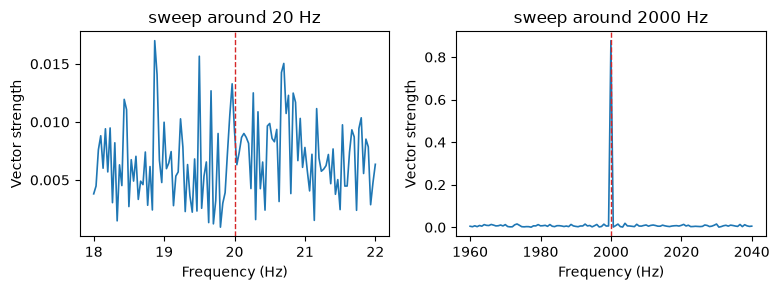

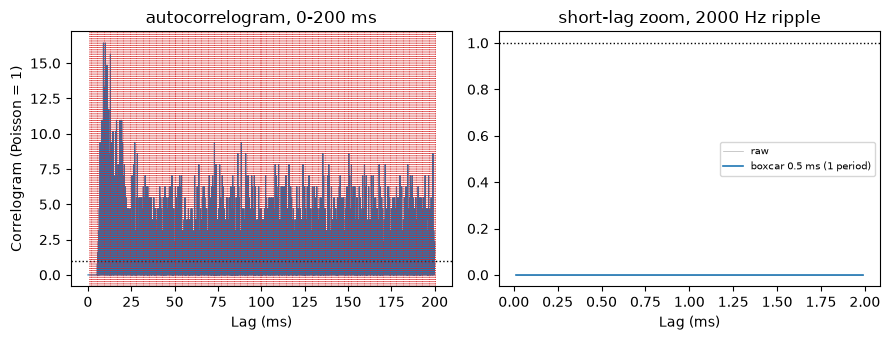

FDR discoveries at q = 0.05: 7 bins (threshold I > 18.17) vs Bonferroni threshold I > 20.03
f0 = 20 Hz: per-bin p = 2.61e-01, BH q = 1.00e+00
f0 = 2000 Hz: per-bin p = 0.00e+00, BH q = 0.00e+00


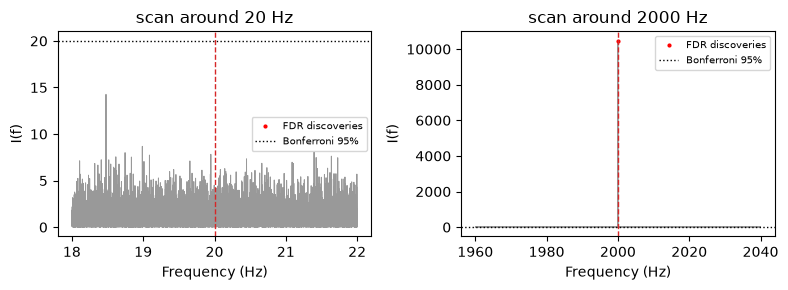

Multitaper sub-record: 250 s, K = 5, resolution +/-12 mHz, power cost vs full record ~ sqrt(20)
f0 = 20 Hz: Mt = 0.69, line-test p = 7.33e-01
f0 = 2000 Hz: Mt = 109.65, line-test p = 3.05e-229
Welch mild (2 Hz res): 19999 segments (50% overlap), sanity mean(Iw) in (100.0, 1000.0) Hz = 1.0005 (expect 1)
Welch heavy (8 Hz res): 79999 segments (50% overlap), sanity mean(Iw) in (100.0, 1000.0) Hz = 1.0005 (expect 1)


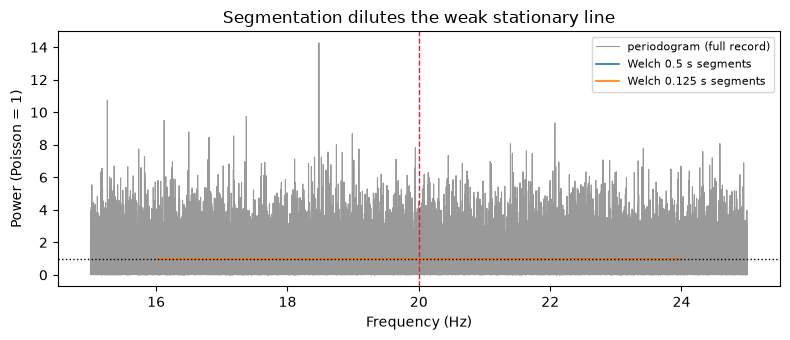

f0 = 20 Hz: jitter window +/-25 ms, observed I = 1.35, max surrogate I = 8.01, surrogate p = 0.2604
f0 = 2000 Hz: jitter window +/-0.25 ms, observed I = 12298.58, max surrogate I = 7.49, surrogate p = 0.0005
 f0 (Hz)  I_periodogram  p_perbin  p_Bonferroni_band  q_BH_fdr  vector_strength  p_Rayleigh_prespecified  p_jitter_surrogate  p_multitaper_subrecord  I_welch_0.5s  I_welch_0.125s
      20           1.34     0.261                  1         1           0.0092                    0.258                0.26                   0.733         0.965           0.984
   2e+03       1.05e+04         0                  0         0            0.877                        0              0.0005               3.05e-229           2.1            1.31

Reading guide:
- p_Rayleigh_prespecified: use when f0 is fixed by the simulation (no multiple-comparisons penalty); equals exp(-I(f0)) and uses exact spike times. With a stationary frequency it is the most powerful test.
- Coherent vs incoherent: the ful

In [40]:
# %% [Cell 1] Configuration and spike-train preparation
import numpy as np
import pandas as pd
from scipy import stats, fft as sfft
from scipy.signal import windows as ssw
import matplotlib.pyplot as plt

# NOTE: use scipy.fft (not numpy.fft) for the large transforms: it keeps
# float32 inputs in single precision internally (complex64 output) and is
# markedly lighter on memory at 5e7-sample scale.

# --- user configuration ----------------------------------------------------
SPIKETIMES_UNIT_MS = True     # True if `spiketimes` is in milliseconds
T_TOTAL   = 5000.0            # total simulated duration, s
DT_AN     = 1e-4              # analysis grid, s (0.1 ms -> Nyquist 5 kHz)
                               # NOTE: binning attenuates line power at
                               # frequency f by sinc^2(pi f DT_AN) in the scan
                               # (26 percent at 3 kHz for DT_AN = 1e-4).
                               # The prespecified tests (Cells 3 and 8) use
                               # exact spike times and are unaffected. For an
                               # unbiased scan up to 3 kHz set DT_AN = 2.5e-5
                               # (the simulation dt); that needs ~4x memory.
BIN_LAG   = 25e-6             # autocorrelogram lag bin, s (simulation dt)
LAG_MAX   = 0.2               # autocorrelogram max lag, s
F0_LIST   = [20, 2000.0]            # frequencies of interest, Hz, e.g. [20.0, 3000.0]
F_MAX     = 3000.0            # upper frequency for the full-band scan, Hz
FLAT_BAND = (100.0, 1000.0)   # reference band for sanity checks, Hz
ALPHA     = 0.05              # significance level
N_SURR    = 2000              # jitter surrogate repetitions per frequency
NW        = 3.0               # multitaper time-bandwidth product
K_TAPERS  = 5                 # number of DPSS tapers (<= 2*NW - 1)
SUBREC_MT = 250.0             # sub-record length, s, for the multitaper cell;
                               # set to None to skip. Full-record DPSS on the
                               # 5e7-bin grid would need several GB of RAM.
                               # Raise to 500-1000 s if your machine allows.
NB_BLOCKS = 10                # blocks for the stationarity check in Cell 3
SEED      = 0
# ---------------------------------------------------------------------------

t = np.sort(np.asarray(spiketimes, dtype=float).ravel())
if SPIKETIMES_UNIT_MS:
    t = t / 1000.0
assert t.size > 0, "spiketimes is empty"
n_out = int(np.sum((t < 0) | (t >= T_TOTAL)))
if n_out:
    print(f"WARNING: {n_out} spikes outside [0, {T_TOTAL}) s are excluded")
    t = t[(t >= 0) & (t < T_TOTAL)]
N   = t.size
lam = N / T_TOTAL
nb  = int(round(T_TOTAL / DT_AN))
k_nyq = nb // 2                       # rfft bins 0..k_nyq cover 0..Nyquist
print(f"N = {N} spikes, mean rate = {lam:.3f} spikes/s, "
      f"mean ISI = {1e3 / lam:.1f} ms")
print(f"Analysis grid: nb = {nb} bins ({nb * 4 / 1e6:.0f} MB as float32), "
      f"frequency resolution = {1 / T_TOTAL * 1e3:g} mHz, "
      f"Nyquist = {k_nyq / T_TOTAL:g} Hz")

def k_of(f):     # frequency (Hz) -> nearest rfft bin index, f_k = k / T_TOTAL
    return int(round(f * T_TOTAL))

def f_of(k):     # rfft bin index -> frequency (Hz)
    return k / T_TOTAL

# %% [Cell 2] Point-process periodogram with Poisson null (full record, no averaging)
# Counts on the analysis grid, kept in float32 to bound memory
# (5e7 bins = 200 MB for a 5000 s record at DT_AN = 1e-4).
idx     = (t / DT_AN).astype(np.int64)
counts  = np.zeros(nb, dtype=np.float32)
np.add.at(counts, idx, 1.0)      # scatter spikes onto the grid (200 MB total)
del idx
D = sfft.rfft(counts)            # float32 -> complex64 via scipy.fft
I = np.abs(D)                    # magnitude, float32
I *= I                           # in-place |D|^2
I /= N                           # unit-mean Exp under homogeneous Poisson H0
del D

# Significance under H0 (homogeneous Poisson): I ~ Exp(1), p = exp(-I) per bin.
# Bin k corresponds to f = k / T_TOTAL; the scan band is bins 1..k_nyq.
M          = k_nyq                 # bins tested -> multiple comparisons
bonf_thr   = np.log(M / ALPHA)     # family-wise threshold across the band
k_lo, k_hi = k_of(FLAT_BAND[0]), k_of(FLAT_BAND[1])
print(f"Bins tested in 1-{F_MAX:g} Hz: {M:.3e}")
print(f"Per-bin 95% line at I = {np.log(1 / ALPHA):.2f}; "
      f"family-wise 95% (Bonferroni) line at I = {bonf_thr:.2f}")
print(f"Sanity check: mean(I) in {FLAT_BAND} Hz = "
      f"{I[k_lo:k_hi + 1].mean():.4f} (expect 1)")

def log_max_pool(Iarr, k_start, k_stop, n_per_decade=100):
    """Decimate the dense spectrum for display: max within log-spaced
    frequency buckets. Operates on bin indices k (f = k / T_TOTAL)."""
    n_e = int(np.ceil(n_per_decade * np.log10(k_stop / k_start))) + 1
    k_edges = np.logspace(np.log10(k_start), np.log10(k_stop), n_e)
    starts = np.unique(np.ceil(k_edges).astype(np.int64)) - 1
    starts = starts[(starts >= 0) & (starts < k_stop - k_start)]
    return f_of(starts + k_start), np.maximum.reduceat(Iarr[k_start:k_stop],
                                                       starts)

fig, ax = plt.subplots(figsize=(9, 4))
f_pool, I_pool = log_max_pool(I, 1, k_nyq + 1)
ax.loglog(f_pool, I_pool, lw=0.6, color="0.5",
          label="periodogram (max per bucket)")
for lvl, lbl in [(np.log(1 / ALPHA), "per-bin 95%"),
                 (bonf_thr, "Bonferroni 95%")]:
    ax.axhline(lvl, color="k", ls=":", lw=1)
    ax.text(1.3, lvl * 1.15, lbl, fontsize=8)
for f0 in F0_LIST:
    ax.axvline(f0, color="C3", ls="--", lw=1)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("I(f)  (Poisson-normalized)")
ax.set_title(f"Point-process periodogram, full {T_TOTAL:g} s record")
ax.set_xlim(1, F_MAX)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

# %% [Cell 3] Vector strength (phase locking) and Rayleigh test at the target frequencies
def vector_strength(ts, f0):
    """Return (R, mean_phase_rad, p_rayleigh) for frequency f0 in Hz."""
    z = np.mean(np.exp(2j * np.pi * f0 * ts))
    R = np.abs(z)
    p = np.exp(-ts.size * R ** 2)     # Rayleigh p, large-N approximation
    return R, np.angle(z), p

vs = {f0: vector_strength(t, f0) for f0 in F0_LIST}
for f0, (R, ph, p) in vs.items():
    p_pd = float(np.exp(-float(I[k_of(f0)])))
    print(f"f0 = {f0:g} Hz: R = {R:.4f}, Rayleigh p = {p:.2e}  "
          f"(binned periodogram p at {f_of(k_of(f0)):.4f} Hz = {p_pd:.2e}; "
          f"equals the Rayleigh p up to the sinc^2(pi f DT_AN) binning loss)")

# Stationarity check: block-wise vector strength and phase coherence.
# Over a long record the no-drift assumption carries the full-record phase
# test; frequency drift would appear as decohering block phases.
edges = np.linspace(0.0, T_TOTAL, NB_BLOCKS + 1)
for f0 in F0_LIST:
    Rb, phb = [], []
    for i in range(NB_BLOCKS):
        tb = t[(t >= edges[i]) & (t < edges[i + 1])]
        R, ph, _ = vector_strength(tb, f0)
        Rb.append(R); phb.append(ph)
    Rb, phb = np.array(Rb), np.array(phb)
    coh = np.abs(np.mean(np.exp(1j * phb)))
    print(f"f0 = {f0:g} Hz, blocks of {T_TOTAL / NB_BLOCKS:g} s: "
          f"R = {Rb.mean():.4f} +/- {Rb.std():.4f}, "
          f"block phase coherence = {coh:.3f} "
          f"(near 1 = stationary phase, near 0 = drift)")

# Frequency sweep of vector strength around each f0
axes = np.atleast_1d(plt.subplots(1, len(F0_LIST),
                                  figsize=(4 * len(F0_LIST), 3))[1])
for ax, f0 in zip(axes, F0_LIST):
    span = max(2.0, 0.02 * f0)
    fr   = f0 + np.linspace(-span, span, 121)
    Rv   = np.abs(np.exp(2j * np.pi * np.outer(fr, t)).mean(axis=1))
    ax.plot(fr, Rv, lw=1.2)
    ax.axvline(f0, color="C3", ls="--", lw=1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Vector strength")
    ax.set_title(f"sweep around {f0:g} Hz")
plt.tight_layout(); plt.show()

# %% [Cell 4] Autocorrelogram from exact pair differences (no giant FFT needed)
# Count all spike pairs with lag in (0, LAG_MAX] at BIN_LAG resolution.
# Normalized so that the Poisson expectation is 1 at every lag.
nlag = int(round(LAG_MAX / BIN_LAG))
h    = np.zeros(nlag)
CH   = 512
for a in range(0, N, CH):
    d = t[a:a + CH, None] - t[None, :]
    m = (d > 0) & (d <= LAG_MAX)
    if m.any():
        hh, _ = np.histogram(d[m], bins=nlag, range=(0.0, LAG_MAX))
        h += hh
lag = (np.arange(nlag) + 0.5) * BIN_LAG
ach = h * T_TOTAL / (N * (N - 1) * BIN_LAG)   # Poisson expectation = 1
# The FFT of this correlogram is the power spectrum (Wiener-Khinchin); the
# periodogram in Cell 2 is its exact discrete counterpart, so it is not
# recomputed here.

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(lag * 1e3, ach, lw=0.8)
axes[0].axhline(1.0, color="k", ls=":", lw=1)
for f0 in F0_LIST:
    if f0 * LAG_MAX >= 3:            # mark periods that fit in the window
        for n in range(1, int(f0 * LAG_MAX) + 1):
            axes[0].axvline(n / f0 * 1e3, color="C3", ls=":", lw=0.6)
axes[0].set_xlabel("Lag (ms)")
axes[0].set_ylabel("Correlogram (Poisson = 1)")
axes[0].set_title(f"autocorrelogram, 0-{LAG_MAX * 1e3:g} ms")
f_hi = max(F0_LIST)
if f_hi >= 100.0:                     # short-lag zoom for high frequencies
    sm = max(1, int(round((1.0 / f_hi) / BIN_LAG)))   # one-period boxcar
    ach_sm = np.convolve(ach, np.ones(sm) / sm, mode="same")
    m2 = lag <= 2e-3
    axes[1].plot(lag[m2] * 1e3, ach[m2], lw=0.5, color="0.7", label="raw")
    axes[1].plot(lag[m2] * 1e3, ach_sm[m2], lw=1.2,
                 label=f"boxcar {sm * BIN_LAG * 1e3:g} ms (1 period)")
    axes[1].axhline(1.0, color="k", ls=":", lw=1)
    axes[1].set_xlabel("Lag (ms)")
    axes[1].set_title(f"short-lag zoom, {f_hi:g} Hz ripple")
    axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# %% [Cell 5] Omnibus scan significance: Bonferroni and Benjamini-Hochberg FDR
# With ~2.5e7 bins the Bonferroni threshold is very conservative; the FDR
# procedure controls the expected false-discovery proportion instead and is
# the appropriate tool for a broad search. All heavy steps are chunked to
# keep the memory footprint near 300 MB.
p_band = np.exp(-I[1:k_nyq + 1])          # scan p-values (float32, 100 MB)
ps     = np.sort(p_band)                  # ascending, retained for Cell 9
del p_band

def bh_klast(ps_sorted, alpha):
    """Largest rank r (1-based) with p_(r) <= alpha * r / M; 0 if none.
    Chunked scan of the sorted p-values (bounds memory)."""
    M = ps_sorted.size
    klast, CH = 0, 1_000_000
    for j0 in range(0, M, CH):
        r = np.arange(j0 + 1, min(j0 + CH, M) + 1, dtype=np.float64)
        sel = np.nonzero(ps_sorted[j0:j0 + CH] <= alpha * r / M)[0]
        if sel.size:
            klast = j0 + int(sel[-1]) + 1
    return klast

def bh_q(p, ps_sorted):
    """BH q-value of p: minimum FDR level at which p is rejected.
    q(p) = min over j >= rank(p) of p_(j) * M / j, chunked."""
    M = ps_sorted.size
    r0 = int(np.searchsorted(ps_sorted, p, side="right"))
    best, CH = 1.0, 1_000_000
    for j0 in range(max(r0 - 1, 0), M, CH):
        j  = np.arange(j0 + 1, min(j0 + CH, M) + 1, dtype=np.float64)
        qj = ps_sorted[j0:j0 + CH].astype(np.float64) * (M / j)
        best = min(best, float(qj.min()))
    return best

klast   = bh_klast(ps, ALPHA)
fdr_thr = float(ps[klast - 1]) if klast > 0 else np.inf  # BH threshold in p
n_disc  = klast
thr_I   = -np.log(fdr_thr) if np.isfinite(fdr_thr) else np.inf

print(f"FDR discoveries at q = {ALPHA}: {n_disc} bins "
      f"(threshold I > {thr_I:.2f}) "
      f"vs Bonferroni threshold I > {bonf_thr:.2f}")
for f0 in F0_LIST:
    p0 = float(np.exp(-float(I[k_of(f0)])))
    print(f"f0 = {f0:g} Hz: per-bin p = {p0:.2e}, BH q = {bh_q(p0, ps):.2e}")

axes = np.atleast_1d(plt.subplots(1, len(F0_LIST),
                                  figsize=(4 * len(F0_LIST), 3))[1])
for ax, f0 in zip(axes, F0_LIST):
    k0   = k_of(f0)
    half = k_of(max(2.0, 0.02 * f0))
    kk   = np.arange(k0 - half, k0 + half + 1)
    ax.plot(f_of(kk), I[kk], lw=0.7, color="0.6")
    if np.isfinite(fdr_thr):
        disc = I[kk] > thr_I
        ax.plot(f_of(kk)[disc], I[kk][disc], "r.", ms=4,
                label="FDR discoveries")
    ax.axhline(bonf_thr, color="k", ls=":", lw=1, label="Bonferroni 95%")
    ax.axvline(f0, color="C3", ls="--", lw=1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("I(f)")
    ax.set_title(f"scan around {f0:g} Hz")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# %% [Cell 6] Multitaper spectrum on a sub-record (optional)
# A full-record DPSS multitaper on the 5e7-bin grid needs several GB, and
# any segment-averaged (incoherent) power estimate loses the coherent gain
# that makes the full-record phase test strong. This cell therefore runs a
# principled multitaper on ONE contiguous sub-record and reports the line
# test at F0, at a documented power cost.
p_mt_sub = {}
if SUBREC_MT:
    nb_sub = int(round(SUBREC_MT / DT_AN))
    k0     = (nb - nb_sub) // 2
    sub    = counts[k0:k0 + nb_sub]
    N_sub  = float(sub.sum())
    tap    = ssw.dpss(nb_sub, NW, Kmax=K_TAPERS)
    Dtaps  = np.array([sfft.rfft(w.astype(np.float32) * sub) for w in tap])
    Mt     = (np.abs(Dtaps) ** 2).mean(axis=0) * nb_sub / N_sub  # E = 1 under H0
    del Dtaps
    p_mt   = stats.chi2.sf(2 * K_TAPERS * Mt, 2 * K_TAPERS)  # 2K*Mt ~ chi2(2K)
    print(f"Multitaper sub-record: {SUBREC_MT:g} s, K = {K_TAPERS}, "
          f"resolution +/-{NW / SUBREC_MT * 1e3:g} mHz, "
          f"power cost vs full record ~ sqrt({T_TOTAL / SUBREC_MT:g})")
    for f0 in F0_LIST:
        kk = int(round(f0 * SUBREC_MT))       # f = kk / SUBREC_MT on sub-grid
        kk = min(kk, Mt.size - 1)
        p_mt_sub[f0] = float(p_mt[kk])
        print(f"f0 = {f0:g} Hz: Mt = {Mt[kk]:.2f}, "
              f"line-test p = {p_mt[kk]:.2e}")

# %% [Cell 7] Welch reference: why segmentation loses a weak stationary line
def welch_periodogram(cnts, T_seg, lam, DT, overlap=0.5):
    """Boxcar-segment periodogram in Poisson-normalized units (mean 1 under H0)."""
    nseg = int(round(T_seg / DT))
    hop  = int(round(nseg * (1 - overlap)))
    Nexp = lam * T_seg                       # expected spikes per segment
    acc  = np.zeros(nseg // 2 + 1)
    n    = 0
    for s in range(0, len(cnts) - nseg + 1, hop):
        acc += np.abs(sfft.rfft(cnts[s:s + nseg])) ** 2
        n   += 1
    return sfft.rfftfreq(nseg, d=DT), acc / (n * Nexp), n

welch_specs = {}
for T_seg, tag in [(0.5, "mild (2 Hz res)"), (0.125, "heavy (8 Hz res)")]:
    welch_specs[T_seg] = welch_periodogram(counts, T_seg, lam, DT_AN)
    f_w, Iw, nseg_used = welch_specs[T_seg]
    mfb = (f_w >= FLAT_BAND[0]) & (f_w <= FLAT_BAND[1])
    print(f"Welch {tag}: {nseg_used} segments (50% overlap), "
          f"sanity mean(Iw) in {FLAT_BAND} Hz = {Iw[mfb].mean():.4f} (expect 1)")

fig, ax = plt.subplots(figsize=(8, 3.5))
f0_lo = min(F0_LIST)
half  = k_of(5.0)
kk    = np.arange(k_of(f0_lo) - half, k_of(f0_lo) + half + 1)
ax.plot(f_of(kk), I[kk], lw=0.8, color="0.6", label="periodogram (full record)")
for (T_seg, (f_w, Iw, _)), col in zip(welch_specs.items(), ["C0", "C1"]):
    mw = (f_w >= f0_lo - 5) & (f_w <= f0_lo + 5)
    ax.plot(f_w[mw], Iw[mw], lw=1.2, color=col,
            label=f"Welch {T_seg:g} s segments")
ax.axhline(1, color="k", ls=":", lw=1)
ax.axvline(f0_lo, color="C3", ls="--", lw=1)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power (Poisson = 1)")
ax.set_title("Segmentation dilutes the weak stationary line")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# %% [Cell 8] Jitter surrogates (nonparametric significance, one ensemble per frequency)
rng    = np.random.default_rng(SEED)
surr_p = {}
for f0 in F0_LIST:
    win = 0.5 / f0                  # half the period: complete phase randomization
    R_obs, _, _ = vector_strength(t, f0)
    stat_obs = N * R_obs ** 2        # equal to I(f0) from exact spike times
    stat_s = np.empty(N_SURR)
    for i in range(N_SURR):
        tj = np.clip(t + rng.uniform(-win, win, size=N), 0.0, T_TOTAL)
        z  = np.mean(np.exp(2j * np.pi * f0 * tj))
        stat_s[i] = N * np.abs(z) ** 2
    surr_p[f0] = (1 + np.sum(stat_s >= stat_obs)) / (N_SURR + 1)
    print(f"f0 = {f0:g} Hz: jitter window +/-{win * 1e3:.4g} ms, "
          f"observed I = {stat_obs:.2f}, max surrogate I = {stat_s.max():.2f}, "
          f"surrogate p = {surr_p[f0]:.4f}")
    # The window is scaled to the target period: it destroys structure AT f0
    # while preserving rate modulations slower than the window. Use a separate
    # ensemble per frequency band; one shared ensemble tests only one band.

# %% [Cell 9] Summary
rows = []
for f0 in F0_LIST:
    k     = k_of(f0)
    R, _, p_ray = vs[f0]
    p0    = float(np.exp(-float(I[k])))
    row = {"f0 (Hz)": f0,
           "I_periodogram": float(I[k]),
           "p_perbin": p0,
           "p_Bonferroni_band": min(1.0, M * p0),
           "q_BH_fdr": bh_q(p0, ps),
           "vector_strength": R,
           "p_Rayleigh_prespecified": p_ray,
           "p_jitter_surrogate": surr_p[f0]}
    if p_mt_sub:
        row["p_multitaper_subrecord"] = p_mt_sub[f0]
    for T_seg in welch_specs:
        f_w, Iw, _ = welch_specs[T_seg]
        row[f"I_welch_{T_seg:g}s"] = float(Iw[int(np.argmin(np.abs(f_w - f0)))])
    rows.append(row)
df = pd.DataFrame(rows)
print(df.to_string(index=False, float_format=lambda x: f"{x:.3g}"))
print("\nReading guide:")
print("- p_Rayleigh_prespecified: use when f0 is fixed by the simulation "
      "(no multiple-comparisons penalty); equals exp(-I(f0)) and uses exact "
      "spike times. With a stationary frequency it is the most powerful test.")
print("- Coherent vs incoherent: the full-record phase test gains roughly "
      "sqrt(n_segments) over any power-averaged estimator (Welch, segmented "
      "multitaper); that is why the line vanishes in Cell 7.")
print("- q_BH_fdr: expected false-discovery proportion among all bins "
      "rejected at this level; the honest omnibus criterion for a broad scan.")
print("- p_jitter_surrogate: valid even when the Poisson null is violated "
      "(refractoriness, ISI correlations); scale the window to each f0.")

In [41]:
# %% [Cell 12] Standalone prespecified-frequency analysis: spike train -> p
# Self-contained: needs only `spiketimes` and F0_LIST. No FFT, no spectrum
# scanning, no Bonferroni: the frequency is fixed in advance, so p = exp(-I)
# is the final answer. Exact spike times -> no binning loss at any f0.
import numpy as np
import pandas as pd
from scipy import stats

SPIKETIMES_UNIT_MS = True      # False if spiketimes are already in seconds
ALPHA = 0.05
N_SURR = 999                   # jitter surrogates (assumption-free p)


def analyze_line(spiketimes, f0, unit_ms=SPIKETIMES_UNIT_MS,
                 alpha=ALPHA, n_surr=N_SURR, rng=None):
    """Exact test of rate(t) = lambda0 * (1 + m*cos(2*pi*f0*t + phi)).

    Statistic: I = N * R^2 with R = |sum exp(2j*pi*f0*t_j)| / N.
    Null (homogeneous Poisson): I ~ Exp(1) = chi2_2 / 2. This IS the
    'squared-Gaussian' distribution of a periodogram ordinate: Re/Im of the
    Fourier sum are Gaussian by the CLT, and |Gaussian|^2 is chi2_2/2.
    p = exp(-I) is its exact CDF (accurate to O(1/N) at N ~ 15000).
    Signal: E[I] = 1 + N*m^2/4, so m_ML = 2*sqrt(max(I-1, 0)/N).
    """
    t = np.asarray(spiketimes, float)
    if unit_ms:
        t = t / 1000.0                      # -> seconds
    N = t.size
    z = np.exp(2j * np.pi * f0 * t).sum()
    R = abs(z) / N
    I = N * R ** 2
    p = np.exp(-I)                           # exact Exp(1) tail, NOT Gaussian

    # --- 95% CI for m from the noncentral chi2: 2I ~ ncx2(2, nu), nu = N*m^2/2
    x = 2.0 * I

    def cdf(nu):                             # P(X <= x | nu), decreasing in nu
        return stats.ncx2.cdf(x, 2, nu)

    def bisect(target, lo, hi):
        for _ in range(60):
            mid = 0.5 * (lo + hi)
            if cdf(mid) > target:
                lo = mid
            else:
                hi = mid
        return 0.5 * (lo + hi)

    hi = max(x, 1.0)
    while cdf(hi) > alpha / 2:
        hi *= 2.0
    nu_hi = bisect(alpha / 2, 0.0, hi)
    nu_lo = 0.0 if cdf(0.0) < 1 - alpha / 2 else bisect(1 - alpha / 2, 0.0, nu_hi)
    m_lo, m_hi = np.sqrt(2 * nu_lo / N), np.sqrt(2 * nu_hi / N)
    m_ml = 2 * np.sqrt(max(I - 1.0, 0.0) / N)  # debiased; 2*R is biased +1/sqrt(N)

    # --- Jitter surrogates: uniform shift within one period destroys phase
    # coherence at f0 while preserving structure on longer time scales.
    # Assumption-free companion to the exact p (valid under refractoriness).
    rng = rng or np.random.default_rng(0)
    half = 0.5 / f0
    cnt = 1
    for _ in range(n_surr):
        ts = t + rng.uniform(-half, half, N)
        cnt += int(abs(np.exp(2j * np.pi * f0 * ts).sum()) / N >= R)
    p_surr = cnt / (n_surr + 1)

    return {"f0 (Hz)": f0, "N": N, "I0": I, "p_expnull": p,
            "coherent_SNR": np.sqrt(max(I - 1.0, 0.0)),
            "m_ML": m_ml, "m_CI95_lo": m_lo, "m_CI95_hi": m_hi,
            "p_jitter": p_surr}

rows = [analyze_line(spiketimes, f0) for f0 in F0_LIST]
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

 f0 (Hz)     N       I0  p_expnull  coherent_SNR     m_ML  m_CI95_lo  m_CI95_hi  p_jitter
      20 15987    1.354     0.2583        0.5948 0.009409          0    0.03793     0.261
    2000 15987 1.23e+04          0         110.9    1.754      1.732      1.776     0.001
